In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from sklearn.preprocessing import StandardScaler


In [2]:
df = pd.read_csv(r"D:\Dataset.csv")


In [3]:
df.head(10)

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
5,s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
6,s10,Movie,The Starling,Theodore Melfi,United States,9/24/2021,2021,PG-13,104 min,"Comedies, Dramas"
7,s939,Movie,Motu Patlu in the Game of Zones,Suhas Kadav,India,5/1/2021,2019,TV-Y7,87 min,"Children & Family Movies, Comedies, Music & Mu..."
8,s13,Movie,Je Suis Karl,Christian Schwochow,Germany,9/23/2021,2021,TV-MA,127 min,"Dramas, International Movies"
9,s940,Movie,Motu Patlu in Wonderland,Suhas Kadav,India,5/1/2021,2013,TV-Y7,76 min,"Children & Family Movies, Music & Musicals"


In [4]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in'],
      dtype='object')

In [5]:
df.isnull().sum().sum

<bound method Series.sum of show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64>

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [7]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
8785    False
8786    False
8787    False
8788    False
8789    False
Length: 8790, dtype: bool

In [8]:
df_categorical = df.drop(columns=['release_year',"date_added"])

df_categorical

,show_id,type,title,director,country,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
...,...,...,...,...,...,...,...,...
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,TV-Y,1 Season,Kids' TV


In [9]:
df.describe()

,release_year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


<Axes: xlabel='type', ylabel='count'>

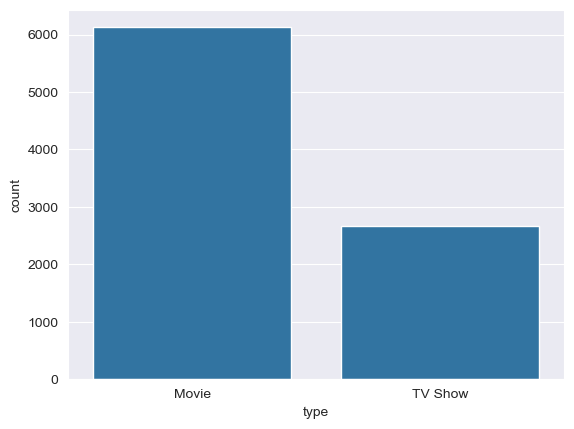

In [10]:
sns.countplot(x = "type" , data = df)


<Axes: ylabel='count'>

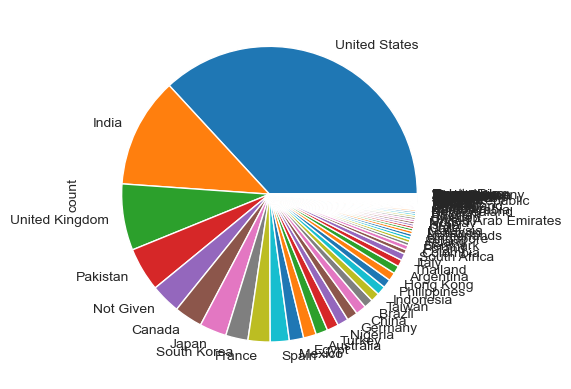

In [11]:
df["country"].value_counts().plot(kind = "pie")

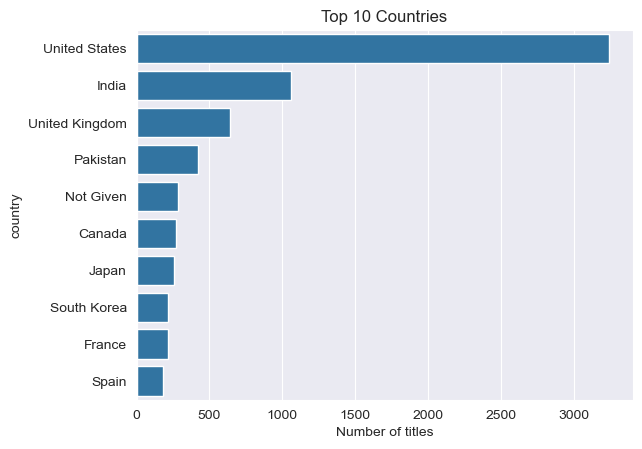

In [12]:
# Top 10 countries
top_countries = (
    df["country"].dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Countries")
plt.xlabel("Number of titles")
plt.show()

Text(0.5, 1.0, 'Top 10 Genres')

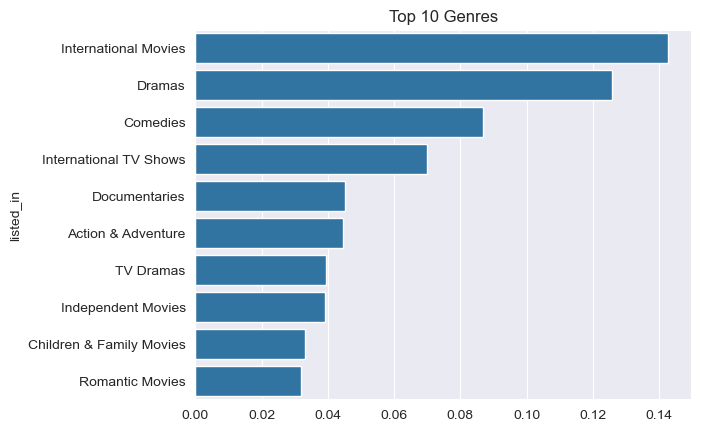

In [13]:
top_genres = (
    df["listed_in"].dropna().str.split(",").explode().str.strip().value_counts(10).head(10)
)
sns.barplot(x = top_genres.values,y = top_genres.index)
plt.title("Top 10 Genres")


<Axes: ylabel='country'>

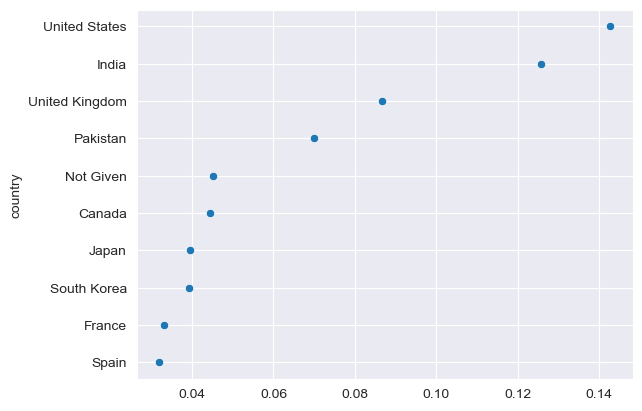

In [14]:
sns.scatterplot(x = top_genres.values,y = top_countries.index)

FROM NETFLIX THIS DATASET WE CAN CLEARLY IDENTIFY THAT MOST OF THE PROGRAMS ARE LISTED FROM UNITED STATES OF AMERICA AND PEOPLE WATCH MORE INTERNATIONAL MOVIES RATHER THAN COMEDY SHOWS OR DRAMAS.


In [15]:
import nltk
nltk.download('stopwords')
import difflib
from difflib import get_close_matches
from sklearn.metrics.pairwise import cosine_similarity



[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\UMAR.TECH\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [16]:
top_year = (df["release_year"].dropna().value_counts().head(10))

In [17]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in'],
      dtype='object')

In [18]:
top_year

release_year
2018    1146
2019    1030
2017    1030
2020     953
2016     901
2021     592
2015     555
2014     352
2013     286
2012     236
Name: count, dtype: int64

<Axes: ylabel='listed_in'>

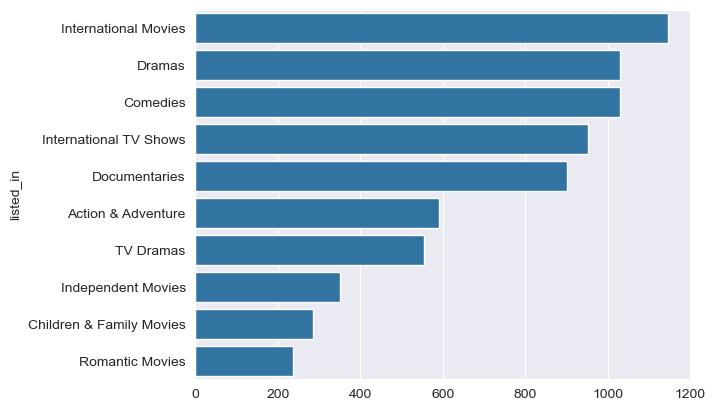

In [19]:
sns.barplot(x = top_year.values,y = top_genres.index)



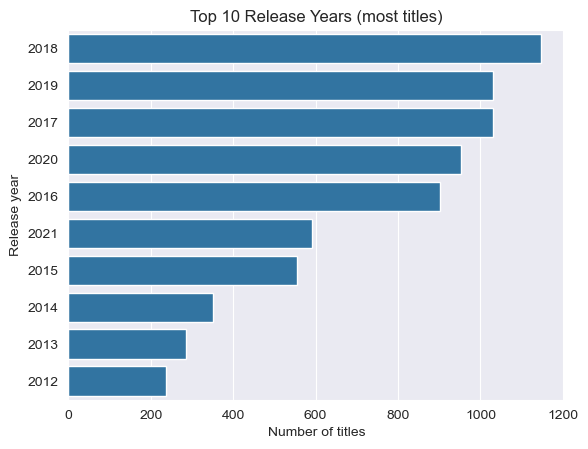

In [20]:
sns.barplot(x=top_year.values, y=top_year.index.astype(str))
plt.title("Top 10 Release Years (most titles)")
plt.xlabel("Number of titles")
plt.ylabel("Release year")
plt.show()

In [21]:
df.head(12)

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
5,s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
6,s10,Movie,The Starling,Theodore Melfi,United States,9/24/2021,2021,PG-13,104 min,"Comedies, Dramas"
7,s939,Movie,Motu Patlu in the Game of Zones,Suhas Kadav,India,5/1/2021,2019,TV-Y7,87 min,"Children & Family Movies, Comedies, Music & Mu..."
8,s13,Movie,Je Suis Karl,Christian Schwochow,Germany,9/23/2021,2021,TV-MA,127 min,"Dramas, International Movies"
9,s940,Movie,Motu Patlu in Wonderland,Suhas Kadav,India,5/1/2021,2013,TV-Y7,76 min,"Children & Family Movies, Music & Musicals"


In [22]:
df["combined_featu"] = df["director"].fillna("") + " " +df["title"].fillna("") + " " +df["listed_in"].fillna("")


df["combined_feature"] = (
    df["director"].fillna("") + " " +
    df["listed_in"].fillna("") + " "
).str.lower()

In [23]:
from sklearn.metrics.pairwise import cosine_similarity

from sklearn.feature_extraction.text import TfidfVectorizer
import pickle

In [24]:
vectorizer = TfidfVectorizer(stop_words='english')

feature = vectorizer.fit_transform(df["combined_feature"])
cs = cosine_similarity(feature)
def recommend(movie,n = 5):
    movie = movie.lower()
    matches = df[df["title"].str.lower() == movie]

    if matches.empty:
        return []
    index= matches.index[0]
    scores = list(enumerate(cs[index]))
    scores = sorted(scores, key=lambda x: x[1], reverse=True)[1:n+1]
    return [df.iloc[i]["title"] for i, _ in scores]
print(recommend("Stranger Things"))

['Nightflyers', 'Stranger Things', 'Helix', 'Manifest', 'The OA']


In [25]:
df["title"]

0                   Dick Johnson Is Dead
1                              Ganglands
2                          Midnight Mass
3       Confessions of an Invisible Girl
4                                Sankofa
                      ...               
8785                          Yunus Emre
8786                           Zak Storm
8787                  Zindagi Gulzar Hai
8788                                Yoko
8789                                 YOM
Name: title, Length: 8790, dtype: object

In [26]:
def genre_overlap(title, n=5):
    recs = recommend(title, n)
    if not recs:
        return None
    base = set(g.strip() for g in df[df["title"] == title]["listed_in"].iloc[0].split(","))
    scores = []
    for r in recs:
        g = set(x.strip() for x in df[df["title"] == r]["listed_in"].iloc[0].split(","))
        scores.append(len(base & g) / len(base | g))   # Jaccard similarity
    return sum(scores) / len(scores)

print(genre_overlap("Stranger Things")*100)

80.0


In [27]:
sample = df["title"].sample(50,random_state=42)
scores = [genre_overlap(t) for t in sample]
scores = [s for s in scores if scores is not None]
average_genre_overlap  = sum(scores) / len(scores)
print(average_genre_overlap)

0.6731999999999999


In [29]:
yearly  = df["release_year"].value_counts().sort_index()
yearly = yearly[(yearly.index >= 2000) & (yearly.index <= 2020)]


In [30]:
print(yearly)

release_year
2000      37
2001      45
2002      51
2003      59
2004      64
2005      80
2006      96
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
Name: count, dtype: int64


Text(0, 0.5, 'Release Year values')

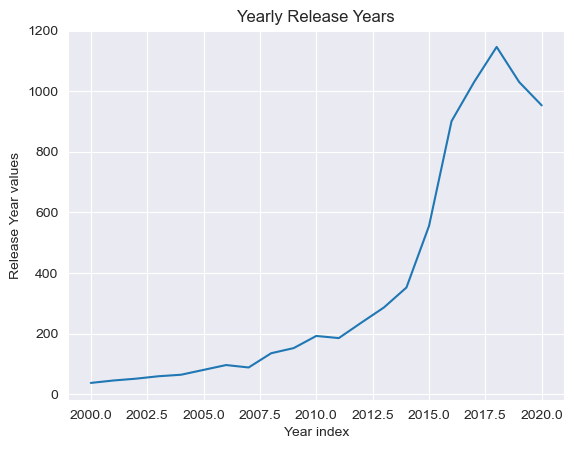

In [31]:
plt.plot(yearly.index,yearly.values)
plt.title("Yearly Release Years")
plt.xlabel("Year index")
plt.ylabel("Release Year values" )


In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from statsmodels.tsa.holtwinters import ExponentialSmoothing


In [39]:
train = yearly.iloc[:-3]
test = yearly.iloc[-3:]
lr = LinearRegression().fit(train.index.values.reshape(-1,1), train.values)
lr_pred = lr.predict(test.index.values.reshape(-1,1))

hw = ExponentialSmoothing(train.values, trend="add").fit()
hw_pred = hw.forecast(3)

for name,p in (["LinearRegression" , lr_pred],["Holt" , hw_pred]):
    mse = mean_squared_error(test.values,p)
    rmse = np.sqrt(mean_squared_error(test.values,p))
    print(f" {name} and its accurcy in mse is :{mse:.1f} and in rmse is :{rmse:.1f}")


 LinearRegression and its accurcy in mse is :116240.1 and in rmse is :340.9
 Holt and its accurcy in mse is :178620.4 and in rmse is :422.6


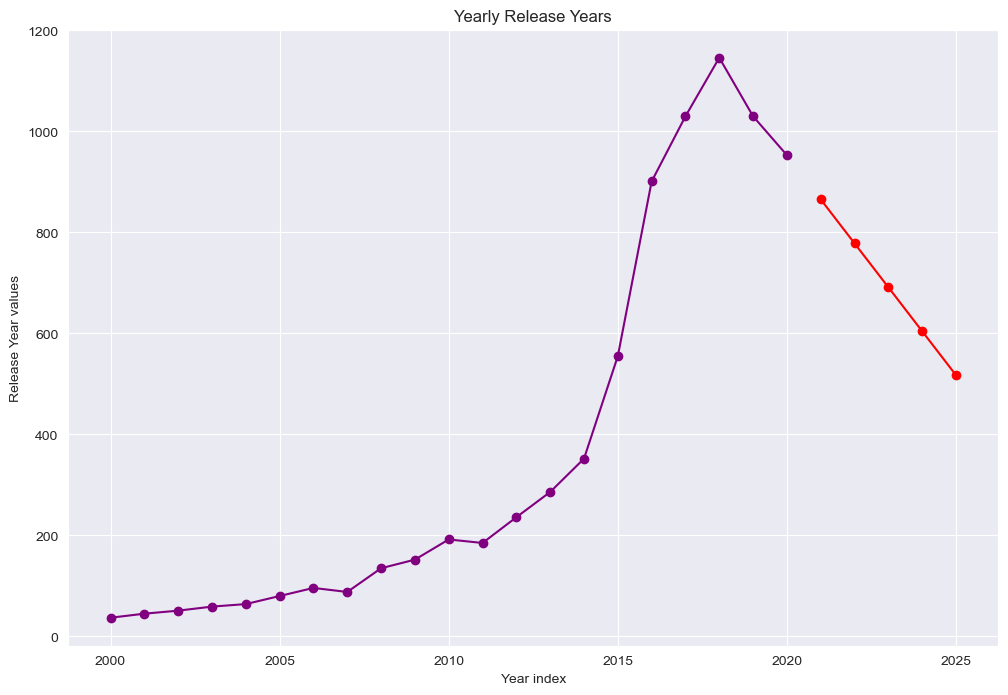

In [46]:
final = ExponentialSmoothing(yearly.values, trend="add").fit()
future = np.arange(yearly.index.max() +1,yearly.index.max() + 6)
pred = final.forecast(5)


plt.figure(figsize=(12,8))
plt.plot(yearly.index,yearly.values,marker='o',c = "purple")
plt.plot(future,pred,c = "r",marker='o' )
plt.title("Yearly Release Years")
plt.xlabel("Year index")
plt.ylabel("Release Year values" )
plt.show()



“2000 se 2018 tak Netflix pe titles ki tadaad mein tezi se izafa hua, jis ke baad 2019-2020 mein thora low nazar aaya. Do models (Linear Regression aur Holt) compare kiye gaye, aur linearregression ka error kam raha. Forecast ke mutabiq agle 5 saal mein ghatne ki traf ishara hai.”

In [47]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [49]:
data = df[["type", "release_year", "rating", "country", "listed_in"]].copy()
data = data.dropna()


data["country"] = data["country"].str.split(",").str[0].str.strip()
data["genre"] = data["listed_in"].str.split(",").str[0].str.strip()

In [75]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["rating", "country"]),
    ("txt", TfidfVectorizer(tokenizer=lambda s: [g.strip() for g in s.split(",")], token_pattern=None),
     "listed_in"),
], remainder="passthrough")


models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}
for c in ["rating", "country", "listed_in"]:
    x_train[c] = x_train[c].fillna("")
    x_test[c] = x_test[c].fillna("")
pipes = {}
for name, m in models.items():
    pipes[name] = Pipeline([("pre", pre), ("model", m)])
    pipes[name].fit(x_train, y_train)

In [78]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

for name, p in pipes.items():
    pred = p.predict(x_test)
    print(name)
    print(classification_report(y_test, pred))


Logistic Regression
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1197
     TV Show       1.00      1.00      1.00       561

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758

Decision Tree
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1197
     TV Show       1.00      1.00      1.00       561

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758

Random Forest
              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1197
     TV Show       1.00      1.00      1.00       561

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00   

                     Accuracy
Logistic Regression       1.0
Decision Tree             1.0
Random Forest             1.0


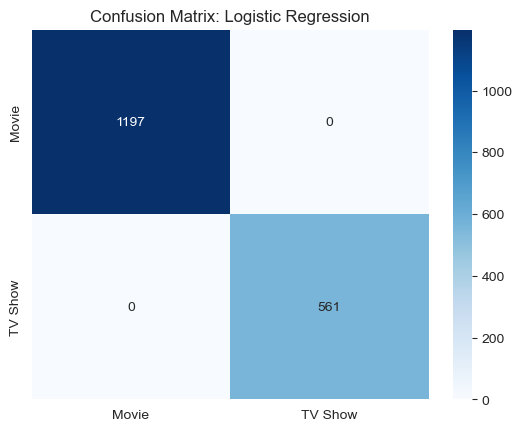

In [81]:
results = pd.DataFrame({
    name: {
        "Accuracy": accuracy_score(y_test, p.predict(x_test)),
    } for name, p in pipes.items()
}).T

print(results.sort_values("Accuracy", ascending=False))

best = results["Accuracy"].idxmax()
cm = confusion_matrix(y_test, pipes[best].predict(x_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=pipes[best].classes_, yticklabels=pipes[best].classes_)
plt.title(f"Confusion Matrix: {best}")
plt.show()